<div style="background:linear-gradient(100deg,#0f2a3d 0%,#17868c 100%);color:#ffffff;padding:28px 32px;border-radius:10px">
<div style="font-size:13px;letter-spacing:3px;opacity:.85;text-transform:uppercase">Monitoría · Maestría en Analítica</div>
<h1 style="margin:8px 0 6px 0;font-size:34px;color:#ffffff">Del <code style="color:#ffd166">for</code> al vector</h1>
<div style="font-size:18px;opacity:.95">List comprehensions y NumPy, hasta programar un gradiente descendente en una sola línea</div>
</div>

In [145]:
import matplotlib.pyplot as plt

# Estética de las gráficas (puro gusto, pueden cambiarla)
INK, TEAL, AMBER, RED, PLUM = "#0f2a3d", "#17868c", "#f0a202", "#c1292e", "#5b3a70"
plt.rcParams.update({
    "figure.figsize": (9, 4.2), "figure.dpi": 110,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linestyle": ":",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.edgecolor": "#9bb0bd",
    "font.size": 10.5, "axes.prop_cycle": plt.cycler(color=[TEAL, AMBER, RED, PLUM, INK]),
})

print("Python :", sys.version.split()[0])
print("NumPy  :", np.__version__)

Python : 3.12.6
NumPy  : 2.4.5


# List comprehensions

Anatomía de una list comprehension:

**[ expresión - for item in iterable - ***if condición***]**

In [2]:
# El mismo resultado, dos opciones distintas de escritura
cuadrados_opcion_a = [1, 4, 9, 16, 25, 36, 49, 64, 81, 100]

# Opción B: Usando comprensión de listas
cuadrados_opcion_b = [x**2 for x in range(1, 11)]

print ("Cuadrados usando la opción A:", cuadrados_opcion_a)
print ("Cuadrados usando la opción B:", cuadrados_opcion_b)

Cuadrados usando la opción A: [1, 4, 9, 16, 25, 36, 49, 64, 81, 100]
Cuadrados usando la opción B: [1, 4, 9, 16, 25, 36, 49, 64, 81, 100]


In [3]:
edades = [15, 22, 18, 30, 25, 17, 19, 21, 50, 60, 15, 16, 17, 18, 19, 20]

# Filtrar edades mayores o iguales a 18 usando comprensión de listas
mayores_de_edad = [x for x in edades if x >= 18]

print("Edades mayores o iguales a 18:", mayores_de_edad)

Edades mayores o iguales a 18: [22, 18, 30, 25, 19, 21, 50, 60, 18, 19, 20]


In [6]:
# Filtrar edades mayores o iguales a 18 usando comprensión de listas
etiquetas_mayores_de_edad = ["adulto" if x >=18 else "menor" for x in edades]

print("Edades mayores o iguales a 18:", etiquetas_mayores_de_edad)

Edades mayores o iguales a 18: ['menor', 'adulto', 'adulto', 'adulto', 'adulto', 'menor', 'adulto', 'adulto', 'adulto', 'adulto', 'menor', 'menor', 'menor', 'adulto', 'adulto', 'adulto']


In [5]:
# Forma alternativa de escribir la comprensión de listas con un bucle for
etiquetas_mayores_de_edad=[]

for x in edades:
    if x >= 18:
        etiquetas_mayores_de_edad.append("adulto")
    else:
        etiquetas_mayores_de_edad.append("menor")

print("Edades mayores o iguales a 18:", etiquetas_mayores_de_edad)

Edades mayores o iguales a 18: ['menor', 'adulto', 'adulto', 'adulto', 'adulto', 'menor', 'adulto', 'adulto', 'adulto', 'adulto', 'menor', 'menor', 'menor', 'adulto', 'adulto', 'adulto']


# Numpy

Es una librería que nos permite trabajar matrices en python de forma muy ligera


In [18]:
# Importar numpy para trabajar con matrices
import numpy as np
import sys, time

In [19]:
lista = list(range(1, 1000001)) # Lista de Python
array = np.arange(1, 1000001) # Numpy array

def cronometrar(fn, repeticiones=3):
    """Corre fn varias veces y devuelve el mejor tiempo en milisegundos."""
    tiempos = []
    for _ in range(repeticiones):
        t0 = time.perf_counter()
        fn()
        tiempos.append(time.perf_counter() - t0)
    return min(tiempos) * 1000

def con_for():
    total = 0
    for x in lista:
        total += x**2
    return total

resultados = {
    "for clásico":        cronometrar(con_for),
    "NumPy":              cronometrar(lambda: (array**2).sum()),
}

base = resultados["NumPy"]
print(f"{'método':<20} {'tiempo (ms)':>12}  {'veces más lento':>16}\n" + "─"*56)
for nombre, ms in resultados.items():
    barra = "█" * int(30 * ms / max(resultados.values()))
    print(f"{nombre:<20} {ms:>12.1f}  {ms/base:>15.1f}x  {barra}")

método                tiempo (ms)   veces más lento
────────────────────────────────────────────────────────
for clásico                  34.9             17.5x  ██████████████████████████████
NumPy                         2.0              1.0x  █


## Cómo crear arrays

In [35]:
print(np.zeros(5)) # Crea un array de ceros de tamaño 5
print(np.ones(5))  # Crea un array de unos de tamaño 5
print(np.full(5, 7)) # Crea un array de tamaño 5 lleno de 7s
print(np.arange(9)) # Crea un array con valores de 0 a 8
print(np.arange(1, 10, 2)) # Crea un array con valores de 1 a 9 con paso de 2
print(np.eye(5)) # Crea una matriz identidad de tamaño 3x3

[0. 0. 0. 0. 0.]
[1. 1. 1. 1. 1.]
[7 7 7 7 7]
[0 1 2 3 4 5 6 7 8]
[1 3 5 7 9]
[[1. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0.]
 [0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 1.]]


In [36]:
print(np.array([[5, 7, 8], [7, 5, 6], [7, 6, 9]])) # Crea un array bidimensional

[[5 7 8]
 [7 5 6]
 [7 6 9]]


In [38]:
rng = np.random.default_rng(seed=42) # Crea un generador de números aleatorios con una semilla específica

In [46]:
print(rng.random(4).round(5)) # Crea un array de 4 números aleatorios entre 0 y 1, redondeados a 5 decimales
print(rng.integers(1, 100, size=4)) # Crea un array de 4 números enteros aleatorios entre 1 y 9

print(rng.integers(1, 100, size=(5,5))) # Crea un array de 5 x 5 de números enteros aleatorios entre 1 y 9

[0.22691 0.66981 0.43715 0.83268]
[63 70 10 31]
[[77 83 44 80 84]
 [39 89 29 24 68]
 [64 14 83 20 80]
 [ 1 79 78 78 66]
 [47 70 28 78 56]]


## Anatomía de un array

In [59]:
ejemplo = rng.integers(1, 100, size=(4,5))
print(ejemplo) # Muestra el array generado

[[93 83 94  3 46]
 [22 91 71 32 56]
 [60 50 47  6 45]
 [35 82 86 75  4]]


In [60]:
print(ejemplo.shape) # Muestra la forma del array
print(ejemplo.size) # Muestra el número total de elementos del array
print(ejemplo.ndim) # Muestra el número de dimensiones del array
print(ejemplo.nbytes) # Muestra el número de bytes que ocupa el array

(4, 5)
20
2
160


## Cambios de forma de los arrays

In [63]:
print(ejemplo.T) # Muestra la transpuesta del array
print(ejemplo.flatten()) # Muestra el array aplanado
print(ejemplo.reshape(2,10)) # Muestra el array reestructurado a 2 filas y 10 columnas

[[93 22 60 35]
 [83 91 50 82]
 [94 71 47 86]
 [ 3 32  6 75]
 [46 56 45  4]]
[93 83 94  3 46 22 91 71 32 56 60 50 47  6 45 35 82 86 75  4]
[[93 83 94  3 46 22 91 71 32 56]
 [60 50 47  6 45 35 82 86 75  4]]


In [76]:
ejemplo_1 = rng.integers(1, 100, size=(4,5))
ejemplo_2 = rng.integers(1, 100, size=(4,5))
ejemplo_3 = rng.integers(1, 100, size=(4,5))

In [65]:
print(ejemplo_1) 
print(ejemplo_2)
print(ejemplo_3)

[[84 40 42 94 86]
 [ 6 36 75 54 26]
 [52 86 23 74 73]
 [88 30 22 55 53]]
[[41 78 80 25 79]
 [23 41  3 34 95]
 [44 71 11 63 37]
 [74 92 53 11 48]]
[[13 45  7 64 31]
 [20  2 88 83 81]
 [ 6 35 97 58 13]
 [14 27 97 17 90]]


In [66]:
# Apilar arrays
print(np.vstack((ejemplo_1, ejemplo_2, ejemplo_3))) # Apila verticalmente los arrays
print(np.hstack((ejemplo_1, ejemplo_2, ejemplo_3))) # Apila horizontalmente los arrays

[[84 40 42 94 86]
 [ 6 36 75 54 26]
 [52 86 23 74 73]
 [88 30 22 55 53]
 [41 78 80 25 79]
 [23 41  3 34 95]
 [44 71 11 63 37]
 [74 92 53 11 48]
 [13 45  7 64 31]
 [20  2 88 83 81]
 [ 6 35 97 58 13]
 [14 27 97 17 90]]
[[84 40 42 94 86 41 78 80 25 79 13 45  7 64 31]
 [ 6 36 75 54 26 23 41  3 34 95 20  2 88 83 81]
 [52 86 23 74 73 44 71 11 63 37  6 35 97 58 13]
 [88 30 22 55 53 74 92 53 11 48 14 27 97 17 90]]


## Copiar arrays

In [77]:
ejemplo_1

array([[68, 92, 82, 33, 82],
       [17, 29, 21, 14,  9],
       [19, 12, 38,  8,  7],
       [98,  9,  8,  3, 14]])

In [ ]:
#SIEMPRE copiar los arrays así
ejemplo_2 = ejemplo_1.copy() 

In [79]:
ejemplo_2[0,0] = 999

In [80]:
ejemplo_1

array([[68, 92, 82, 33, 82],
       [17, 29, 21, 14,  9],
       [19, 12, 38,  8,  7],
       [98,  9,  8,  3, 14]])

In [81]:
ejemplo_2

array([[999,  92,  82,  33,  82],
       [ 17,  29,  21,  14,   9],
       [ 19,  12,  38,   8,   7],
       [ 98,   9,   8,   3,  14]])

## Indexing y slicing

In [ ]:
# Traer el elemento de la fila 0 y columna 3
ejemplo_1[0,3]

np.int64(33)

In [ ]:
# Traer toda la fila 3
ejemplo_1[3,:]

array([98,  9,  8,  3, 14])

In [84]:
# Traer toda la columna 3
ejemplo_1[:,3]

array([33, 14,  8,  3])

In [88]:
# Traer la fila 0, pero solo las columnas 0 y 12
ejemplo_1[-1, [0,1,2]]

array([98,  9,  8])

## Funciones y agregaciones

In [90]:
numero_cualquiera = 90

In [ ]:
# Arítmetica con números escalares
print(np.sqrt(numero_cualquiera)) # Raíz cuadrada
print(np.abs(-numero_cualquiera)) # Valor absoluto
print(np.pow(numero_cualquiera, 3)) # Potencia

np.int64(729000)

In [95]:
matriz_cualquiera = np.array([[4,9], [25, 81]])

In [98]:
# Arítmetica con matrices
print(np.sqrt(matriz_cualquiera)) # Raíz cuadrada
print(np.abs(-matriz_cualquiera)) # Valor absoluto
print(np.pow(matriz_cualquiera, 3)) # Potencia

[[2. 3.]
 [5. 9.]]
[[ 4  9]
 [25 81]]
[[    64    729]
 [ 15625 531441]]


In [99]:
# Trigonometría con matrices
print(np.sin(matriz_cualquiera)) # Seno
print(np.cos(matriz_cualquiera)) # Coseno
print(np.tan(matriz_cualquiera)) # Tangente
print(np.atan(np.sin(matriz_cualquiera))) # Arco tangente

[[-0.7568025   0.41211849]
 [-0.13235175 -0.62988799]]
[[-0.65364362 -0.91113026]
 [ 0.99120281  0.77668598]]
[[ 1.15782128 -0.45231566]
 [-0.13352641 -0.81099442]]
[[-0.64784051  0.3909095 ]
 [-0.13158697 -0.56210656]]


In [100]:
# Estadística con matrices
print(np.mean(matriz_cualquiera)) # Media
print(np.std(matriz_cualquiera)) # Desviación estándar
print(np.var(matriz_cualquiera)) # Varianza

29.75
30.589009464185008
935.6875


Las *universal functions* operan elemento a elemento sobre todo el array, en C.

| Familia | Ejemplos |
|---|---|
| Aritmética | `np.add`, `np.subtract`, `np.multiply`, `np.power`, `np.abs`, `np.sqrt` |
| Exp / log | `np.exp`, `np.log`, `np.log10`, `np.log1p` |
| Trigonometría | `np.sin`, `np.cos`, `np.arctan`, `np.deg2rad` |
| Redondeo | `np.round`, `np.floor`, `np.ceil`, `np.clip` |
| Estadística | `mean`, `median`, `std`, `var`, `min`, `max`, `percentile`, `quantile`, `corrcoef` |
| Posiciones | `argmin`, `argmax`, `argsort`, `np.unique`, `np.searchsorted` |
| Acumuladas | `cumsum`, `cumprod`, `np.diff` |
| Con NaN | `nanmean`, `nanstd`, `nansum` ← ignoran faltantes |

## Álgebra lineal

In [106]:
A = rng.integers(1, 100, size=(4,4))
B = rng.integers(1, 100, size=(4))
C  = rng.integers(1, 100, size=(4,4))

In [107]:
A

array([[16, 62, 92, 14],
       [33, 69, 62, 67],
       [56, 68, 61,  8],
       [75, 45,  6, 41]])

In [108]:
B

array([44,  9, 99, 23])

In [109]:
C

array([[33, 44, 83, 74],
       [77, 24, 84, 83],
       [46, 55,  4, 76],
       [96, 47, 54, 50]])

In [112]:
print("Multiplicación de matrices", A @ B) # Multiplicación de matrices A y B
print("--------------------------------")
print( A @ C) # Multiplicación de matrices A y C

Multiplicación de matrices [10692  9752  9299  5242]
--------------------------------
[[10878  7910  7660 14022]
 [15686  9667 12401 16231]
 [10658  7827 11036 14824]
 [10152  6637 12243 11791]]


In [113]:
print(A.T) # Transpuesta de la matriz A

[[16 33 56 75]
 [62 69 68 45]
 [92 62 61  6]
 [14 67  8 41]]


In [114]:
print (np.linalg.solve(A, B)) # Resolver el sistema de ecuaciones Ax = B

[-0.96440122  4.13193203 -1.84333734 -1.94016649]


In [115]:
print(np.linalg.inv(A)) # Inversa de la matriz A

[[ 0.04348838 -0.03281014 -0.03675967  0.04593949]
 [-0.09722914  0.05556158  0.09770864 -0.07666066]
 [ 0.06617043 -0.03231045 -0.05458303  0.04085557]
 [ 0.01747952  0.00376467 -0.03201014  0.01851548]]


In [116]:
print(np.linalg.det(A)) # Determinante de la matriz A

-3169996.0000000047


In [117]:
print(np.linalg.eigvals(A)) # Valores propios de la matriz A

[198.71309184 +0.j         -42.39477311 +0.j
  15.34084063+11.87207725j  15.34084063-11.87207725j]


<div style="background:linear-gradient(100deg,#0f2a3d 0%,#5b3a70 100%);color:#fff;padding:24px 28px;border-radius:10px">
<h1 style="margin:6px 0;color:#fff">🎯 K-means a mano, sin scikit-learn</h1>
</div>

In [181]:
P = np.vstack([
    rng.normal([0.0, 0.0], 0.7, size=(60, 2)),
    rng.normal([4.0, 4.0], 0.7, size=(60, 2)),
    rng.normal([10.0, 4.5], 0.7, size=(60, 2)),
])   

K = 3

# K means completo 
centros = P[rng.choice(P.shape[0], K, replace=False)]
historial_centros = [centros]
inercias = []


In [182]:
centros = P[rng.choice(P.shape[0], K, replace=False)]
historial_centros = [centros]
inercias = []

In [183]:
P

array([[-1.26576629e+00, -1.48896828e+00],
       [ 9.60671204e-01,  6.32660091e-01],
       [-7.34507785e-01, -2.09975043e-03],
       [ 7.13654942e-01,  2.93440426e-01],
       [ 1.03756167e-01,  7.66607857e-01],
       [-5.11498733e-01,  2.18249141e-02],
       [-1.24940468e-02, -1.90933433e-01],
       [-2.72863858e-01,  5.10077665e-02],
       [ 2.40852472e-02, -7.33899350e-01],
       [ 5.61257137e-01, -6.83469645e-01],
       [-1.52763411e-01, -2.06696331e-01],
       [ 2.50672529e-01, -1.48337276e+00],
       [ 6.23636870e-01, -4.73893243e-01],
       [ 8.53974306e-01, -3.34715447e-01],
       [-3.41905100e-02,  1.33965023e+00],
       [-1.94136746e-01,  8.67194919e-01],
       [ 2.73315599e-02,  2.90793181e-01],
       [ 4.89710126e-02,  5.93496138e-01],
       [-4.79872129e-01, -6.88833966e-01],
       [-4.47003333e-01,  6.97972634e-02],
       [-1.54573150e-01,  4.97192414e-01],
       [ 9.13312190e-01, -6.83086836e-01],
       [-5.13764154e-01, -1.00536759e+00],
       [ 1.

In [184]:
for i in range(10):
    # Distancias
    d = np.linalg.norm(P[:, np.newaxis, :] - centros[np.newaxis, :, :], axis=2)
    etiquetas = np.argmin(d, axis=1)
    
    # Inercia
    inercia = (d.min(axis=1)**2).sum()
    inercias.append(inercia)

    # Actualizar centros
    nuevos_centros = np.array([P[etiquetas == k].mean(axis=0) for k in range(K)])
    centros = nuevos_centros

    historial_centros.append(centros)

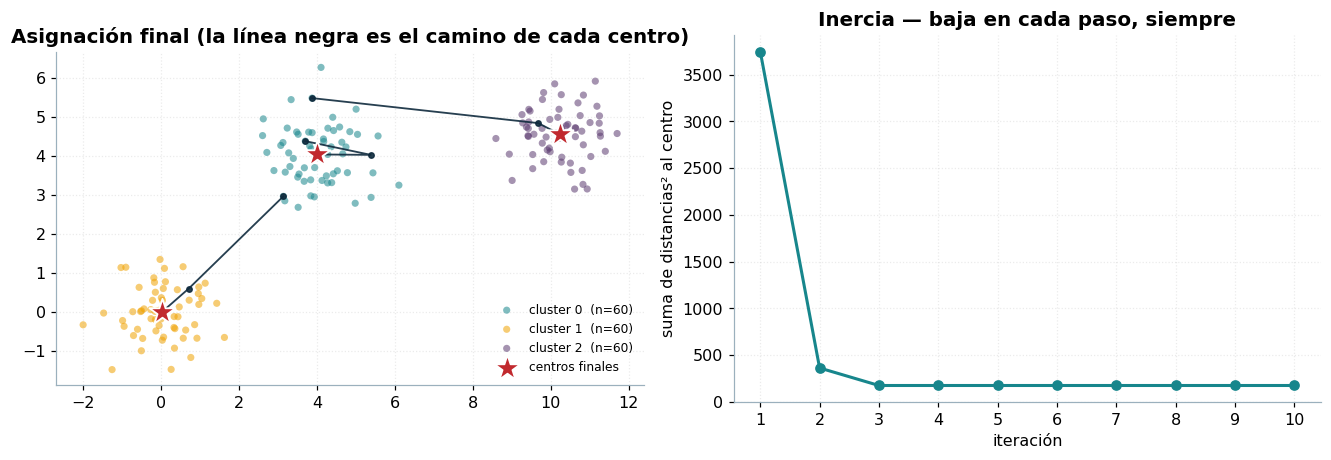

In [185]:
# ── Ver el resultado y el camino que recorrieron los centros ──────────
H = np.array(historial_centros)                     # (iteraciones, K, 2)
colores = [TEAL, AMBER, PLUM]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.3))

for k in range(K):
    pts = P[etiquetas == k]                     # máscara booleana → los puntos del cluster k
    a1.scatter(pts[:, 0], pts[:, 1], s=22, alpha=.55, color=colores[k],
               edgecolor="none", label=f"cluster {k}  (n={len(pts)})")
    a1.plot(H[:, k, 0], H[:, k, 1], "-o", color=INK, ms=3.5, lw=1.2, alpha=.9)

a1.scatter(centros[:, 0], centros[:, 1], marker="*", s=320, color=RED,
           edgecolor="white", linewidth=1.2, zorder=5, label="centros finales")
a1.set_aspect("equal")
a1.set_title("Asignación final (la línea negra es el camino de cada centro)")
a1.legend(fontsize=8, frameon=False, loc="lower right")

a2.plot(range(1, len(inercias)+1), inercias, "o-", color=TEAL, lw=2)
a2.set_title("Inercia — baja en cada paso, siempre")
a2.set_xticks(range(1, len(inercias)+1))
a2.set_xlabel("iteración"); a2.set_ylabel("suma de distancias² al centro")
plt.tight_layout(); plt.show()